<ipython-input-1-75711aca9115>:16: RuntimeWarning: divide by zero encountered in divide
  veff = -G*m * (M1 / np.abs(x - x1) + M2 / np.abs(x - x2))-((m*w**2*x**2)/2)


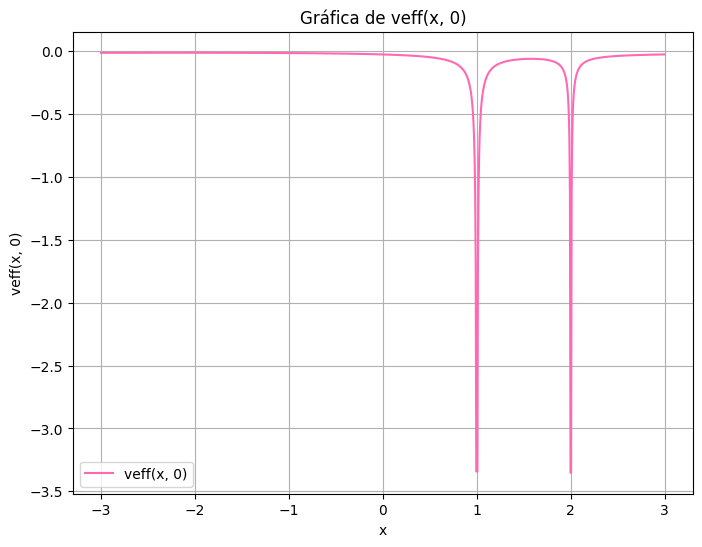

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define las constantes
G = 1 # Constante de gravitación universal
M1 = 1.0  # Masa 1
M2 = 2.0  # Masa 2
x1 = 2.0  # Posición de m1
x2 = 1.0  # Posición de m2, tambien recordando que abs(m1*x1)=abs(m2*x2)
m = 0.01  # cuerpo pequeño
w = np.sqrt(G * (M1 + M2) / (x1 + x2) **3)
# Crear un rango de valores de x
x = np.linspace(-3, 3, 1000)  # Valores de x desde -3 hasta 3

# Calcular la velocidad en función de x
veff = -G*m * (M1 / np.abs(x - x1) + M2 / np.abs(x - x2))-((m*w**2*x**2)/2)

# Grafica en color rosado
plt.figure(figsize=(8, 6))
plt.plot(x, veff, label='veff(x, 0)', color='hotpink')
plt.xlabel('x')
plt.ylabel('veff(x, 0)')
plt.title('Gráfica de veff(x, 0)')
plt.grid(True)
plt.legend()
plt.show()

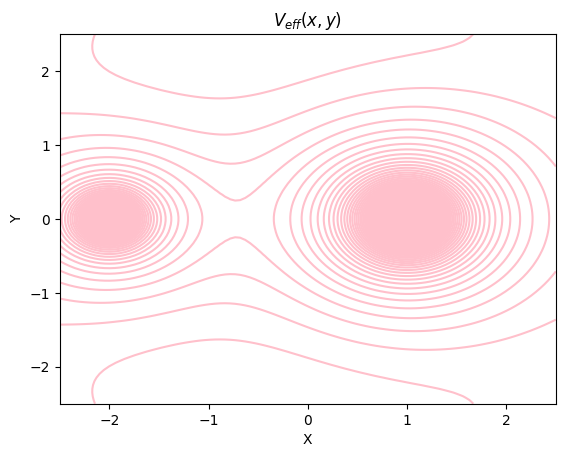

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def Veff(x, y, x1, x2, m, M1, M2, G):

#Se definio las mismas constantes anteriores para encontrar veff(x,y)

    G = 1 #6.67430e-11
    w = np.sqrt(G * (M1 + M2) / (x1 + x2) ** 3)
    r = np.sqrt(x ** 2 + y ** 2)
    r1 = np.sqrt((x + x1) ** 2 + y ** 2)
    r2 = np.sqrt((x - x2) ** 2 + y ** 2)
    veff = -(G * M1 * m) / r1 - (G * M2 * m) / r2 - 0.5 * m * (r ** 2) * w ** 2
    return veff


G = 1
M1 = 1.0
M2 = 2.0
x1 = 2.0
x2 = 1.0
m = 0.01
w = np.sqrt(G * (M1 + M2) / (x1 + x2) ** 3)

x = np.linspace(-2.5, 2.5, 100)
y = np.linspace(-2.5, 2.5, 100)
X, Y = np.meshgrid(x, y)
veff = Veff(X, Y, x1, x2, m, M1, M2, G)

contours = plt.contour(X, Y, veff, levels=650, colors='pink', linestyles='solid')
plt.xlabel('X')
plt.ylabel('Y')
plt.title('$V_{eff}(x, y)$')
#plt.grid()
plt.show()


-0.5021923459262436
0.5021923459262436


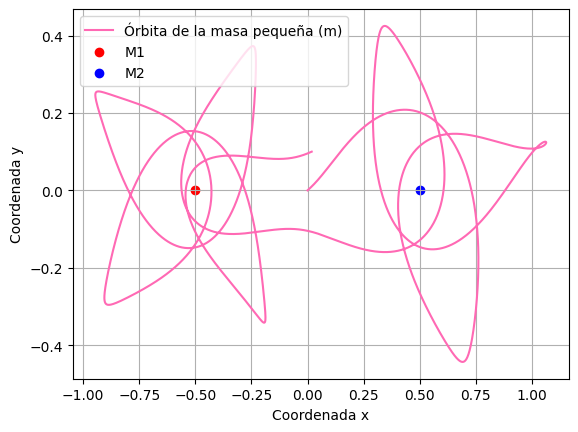

In [ ]:
import numpy as np
import math
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

#para solucionar el sistema de ecuaciones para encontrar la trayectoria de m

# Define las constantes
G = 5
tau = 2
w = 2 * math.pi / tau
M1 = 1
M2 = 1
#Despejando de w = np.sqrt(G * (M1 + M2) / (x1 + x2) ** 3) y sabiendoque  m1*x1=m2*x2
#tambien se puede escribir en x1 y x2 en terminos de w:
x1 = -(M2 / (M1 + M2)**(2/3)) * (G / w**2)**(1/3) #se coloca el menos porque en la ecuacion diferencial tenemos "x-x1"
x2 = (M1 / (M1 + M2)**(2/3)) * (G / w**2)**(1/3)

# Define el sistema de ecuaciones diferenciales
def equations_of_motion(t, state):
    x, y, Dx, Dy = state
    r1 = np.sqrt((x - x1)**2 + y**2)
    r2 = np.sqrt((x - x2)**2 + y**2)
    DDx = -2 * w * Dy + w**2 * x - (G * M1 * (x - x1)) / r1**3 - (G * M2 * (x - x2)) / r2**3
    DDy = 2 * w * Dx + w**2 * y - (G * M1 * y) / r1**3 - (G * M2 * y) / r2**3
    return [Dx, Dy, DDx, DDy]

# Define las condiciones iniciales
x0 = 0.0
y0 = 0.0
vx0 = 2.0
vy0 = 1.0

# Crear una lista con las condiciones iniciales
initial_state = [x0, y0, vx0, vy0]

# Definir el intervalo de tiempo de integración
t_span = (0, 2 * tau)
t_eval = np.linspace(t_span[0], t_span[1], 10000)

# Resolver el sistema de ecuaciones diferenciales
sol = solve_ivp(equations_of_motion, t_span, initial_state, t_eval=t_eval, method='RK45')

# Extraer las componentes de la solución
x_values = sol.y[0]
y_values = sol.y[1]

print(x1)
print(x2)

# Graficar la trayectoria de la pequeña masa
plt.plot(x_values, y_values, label='Órbita de la masa pequeña (m)', color='hotpink')
plt.scatter([x1], [0], color='red', marker='o', label='M1')
plt.scatter([x2], [0], color='b', marker='o', label='M2')
plt.xlabel('Coordenada x')
plt.ylabel('Coordenada y')
plt.legend()
plt.grid()
plt.show()






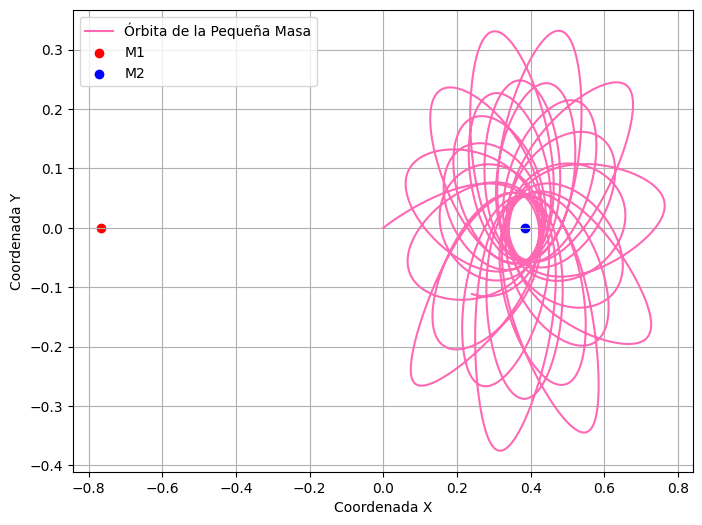

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.integrate import solve_ivp

# Define las constantes
G = 5
tau = 2
w = 2 * math.pi / tau
M1 = 1
M2 = 2

# Define el sistema de ecuaciones diferenciales
def problema_tres_cuerpos_restringido(t, u):
    x, y, Dx, Dy = u
    r1 = np.sqrt((x - x1)**2 + y**2)
    r2 = np.sqrt((x - x2)**2 + y**2)
    DDx = -2 * w * Dy + w**2 * x - (G * M1 * (x - x1)) / r1**3 - (G * M2 * (x - x2)) / r2**3
    DDy = 2 * w * Dx + w**2 * y - (G * M1 * y) / r1**3 - (G * M2 * y) / r2**3
    return [Dx, Dy, DDx, DDy]

#tambien se puede escribir en x1 y x2 en terminos de w
x1 = - (M2 / (M1 + M2)**(2/3)) * (G / w**2)**(1/3)
x2 = (M1 / (M1 + M2)**(2/3)) * (G / w**2)**(1/3)

# Define las condiciones iniciales (posición y velocidad) de la masa pequeña(m)
x0 = 0.0
y0 = 0.0
vx0 = 2
vy0 = 1

# Definir el intervalo de tiempo de integración
t_span = (0, 2 * tau)
t_eval = np.linspace(t_span[0], t_span[1], 10000)


# Resolver el sistema de ecuaciones diferenciales
sol = solve_ivp(problema_tres_cuerpos_restringido, t_span, [x0, y0, vx0, vy0], t_eval=t_eval, method='RK45')

# # Extraer las componentes de la solución
x_values, y_values = sol.y[0], sol.y[1]

# Graficar la trayectoria de la pequeña masa
plt.figure(figsize=(8, 6))
plt.plot(x_values, y_values, label='Órbita de la Pequeña Masa', color='hotpink')
plt.scatter([x1], [0], color='red', marker='o', label='M1')
plt.scatter([x2], [0], color='b', marker='o', label='M2')
plt.xlabel('Coordenada X')
plt.ylabel('Coordenada Y')
#plt.title('Órbita de la Masa Pequeña en el Problema de los Tres Cuerpos Restringido')
plt.legend()
plt.grid()
plt.show()



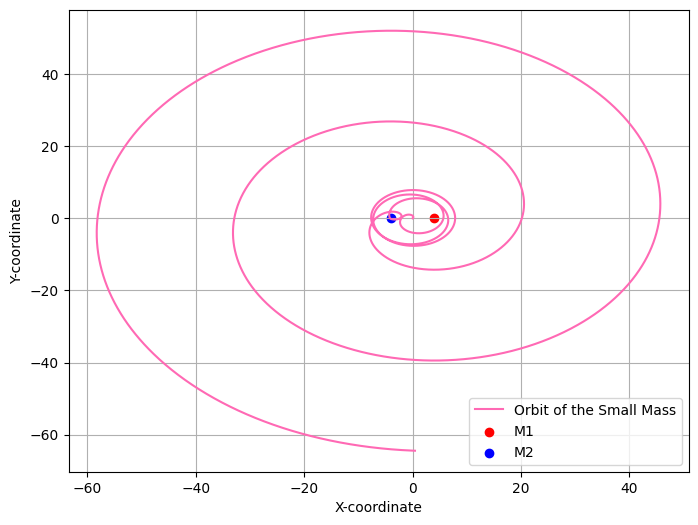

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.integrate import solve_ivp

# Define some constants
G = 5
tau = 4  # Period of Earth-Moon orbit in seconds
w = 2 * math.pi / tau

# Define the restricted three-body problem equations
def restricted_three_body(t, u):
    x, y, Dx, Dy = u
    r1 = np.sqrt((x - x1)**2 + y**2)
    r2 = np.sqrt((x - x2)**2 + y**2)
    DDx = -2 * w * Dy + w**2 * x - (G * M1 * (x - x1)) / r1**3 - (G * M2 * (x - x2)) / r2**3
    DDy = 2 * w * Dx + w**2 * y - (G * M1 * y) / r1**3 - (G * M2 * y) / r2**3
    return [Dx, Dy, DDx, DDy]

# Define the masses of the larger bodies
M1 = 1
M2 = 1

# Define the positions of the larger bodies,
x1 = 4
x2 = -4

# Define the initial conditions of the small mass
x0 = 0.0
y0 = 0.0
vx0 = 1
vy0 = 1

# Set the time span for the simulation
t_span = (0, 6 * tau)
t_eval = np.linspace(t_span[0], t_span[1], 10000)

# Solve the initial value problem using solve_ivp
sol = solve_ivp(restricted_three_body, t_span, [x0, y0, vx0, vy0], t_eval=t_eval, method='RK45')

# Extract the solution components
x_values, y_values = sol.y[0], sol.y[1]

# Plot the orbit of the small mass in 2D space
plt.figure(figsize=(8, 6))
plt.plot(x_values, y_values, label='Orbit of the Small Mass', color='hotpink')
plt.scatter([x1], [0], color='red', marker='o', label='M1')
plt.scatter([x2], [0], color='b', marker='o', label='M2')
plt.xlabel('Coordenada x')
plt.ylabel('Coordenada y')
#plt.title('Orbit of the Small Mass in the Restricted Three-Body Problem')
plt.legend()
plt.grid()
plt.show()

0.012277471
0.9877003172547967


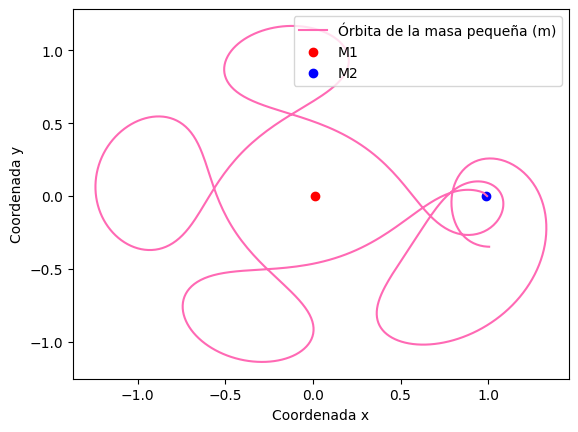

In [ ]:
"Si tomamos tetha´ no como lo toma el goldstein si no que le restamos al angulo (tetha´=tetha-wt), para compensar la rotacion"
"estas contantes y condiciones son proporcionales al modelo de la orbita de la luna"

import numpy as np
import math
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# Define las constantes
G = 1
tau = 2 * math.pi
w = 2 * math.pi / tau
M1 = 0.987722529
M2 = 0.0122777471
#x1 = - (M2 / (M1 + M2)**(2/3)) * (G / w**2)**(1/3)
#x2 = (M1 / (M1 + M2)**(2/3)) * (G / w**2)**(1/3)
x1=0.012277471
x2=M1*x1 / M2

# Define el sistema de ecuaciones diferenciales
def equations_of_motion(t, state):
    x, y, Dx, Dy = state
    r1 = np.sqrt((x + x1)**2 + y**2)
    r2 = np.sqrt((x - x2)**2 + y**2)
    DDx = -2 * w * Dy + w**2 * x - (G * M1 * (x + x1)) / r1**3 - (G * M2 * (x - x2)) / r2**3
    DDy = 2 * w * Dx + w**2 * y - (G * M1 * y) / r1**3 - (G * M2 * y) / r2**3
    return [Dx, Dy, DDx, DDy]

# Define las condiciones iniciales
x0 = 0.994
y0 = 0.0
vx0 = 0.0
vy0 = 2.00158510637908252240537862224

# Crear una lista con las condiciones iniciales
initial_state = [x0, y0, vx0, vy0]

# Definir el intervalo de tiempo de integración
t_span = (0, 4 * tau)
t_eval = np.linspace(t_span[0], t_span[1], 1000)

# Resolver el sistema de ecuaciones diferenciales
sol = solve_ivp(equations_of_motion, t_span, initial_state, t_eval=t_eval, method='RK45')

# Extraer las componentes de la solución
x_values = sol.y[0]
y_values = sol.y[1]

print(x1)
print(x2)

# Graficar la trayectoria de la pequeña masa
plt.plot(x_values, y_values, label='Órbita de la masa pequeña (m)', color='hotpink')
plt.scatter([x1], [0], color='red', marker='o', label='M1')#s=np.sqrt(M1) ** 8)
plt.scatter([x2], [0], color='b', marker='o', label='M2')#s=np.sqrt(M2) ** 8)
plt.xlabel('Coordenada x')
plt.ylabel('Coordenada y')
plt.legend()
#plt.grid()
plt.show()


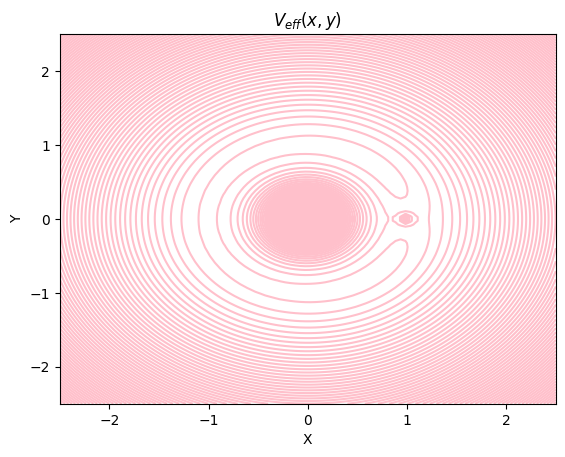

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def Veff(x, y, x1, x2, m, M1, M2, G):
    """
Se definio las mismas constantes anteriores para encontrar el potencial tierra-luna
    """
    w = np.sqrt(G * (M1 + M2) / (x1 + x2) ** 3)
    r = np.sqrt(x ** 2 + y ** 2)
    r1 = np.sqrt((x + x1) ** 2 + y ** 2)
    r2 = np.sqrt((x - x2) ** 2 + y ** 2)
    veff = -(G * M1 * m) / r1 - (G * M2 * m) / r2 - 0.5 * m * (r ** 2) * w ** 2

    return veff


m=0.0001
tau = 2 * math.pi
w = 2 * math.pi / tau
M1 = 0.987722529
M2 = 0.0122777471
#x1 = - (M2 / (M1 + M2)**(2/3)) * (G / w**2)**(1/3)
#x2 = (M1 / (M1 + M2)**(2/3)) * (G / w**2)**(1/3)
x1=0.012277471
x2=M1*x1 / M2

x = np.linspace(-2.5, 2.5, 100)
y = np.linspace(-2.5, 2.5, 100)
X, Y = np.meshgrid(x, y)
veff = Veff(X, Y, x1, x2, m, M1, M2, G)

contours = plt.contour(X, Y, veff, levels=500, colors='pink', linestyles='solid')
plt.xlabel('X')
plt.ylabel('Y')
plt.title('$V_{eff}(x, y)$')
#plt.grid()
plt.show()

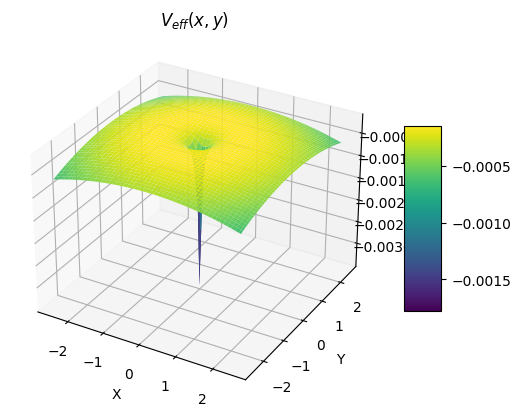

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

#Se definio las mismas constantes anteriores para encontrar el potencial tierra-luna en 3d

def Veff(x, y, x1, x2, m, M1, M2, G):
    w = np.sqrt(G * (M1 + M2) / (x1 + x2) ** 3)
    r = np.sqrt(x ** 2 + y ** 2)
    r1 = np.sqrt((x + x1) ** 2 + y ** 2)
    r2 = np.sqrt((x - x2) ** 2 + y ** 2)
    veff = -(G * M1 * m) / r1 - (G * M2 * m) / r2 - 0.5 * m * (r ** 2) * w ** 2
    return veff

G = 1
tau = 2 * np.pi
w = 2 * np.pi / tau
M1 = 0.987722529
M2 = 0.0122777471
x1 = 0.012277471
x2 = M1 * x1 / M2
m = 0.0001

x = np.linspace(-2.5, 2.5, 100)
y = np.linspace(-2.5, 2.5, 100)
X, Y = np.meshgrid(x, y)
veff = Veff(X, Y, x1, x2, m, M1, M2, G)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(X, Y, veff, cmap='viridis')
fig.colorbar(surf, shrink=0.5, aspect=5)  # Agrega una barra de colores
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('$V_{eff}(x, y)$')
ax.set_title('$V_{eff}(x, y)$')

plt.show()

